In [1]:
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn imbalanced-learn -q


In [2]:
!pip install --upgrade torch torchvision

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import torch
from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection  import train_test_split
from sklearn.preprocessing    import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes      import MultinomialNB, GaussianNB
from sklearn.svm              import LinearSVC
from sklearn.linear_model     import LogisticRegression
from sklearn.ensemble         import RandomForestClassifier
from sklearn.metrics          import (accuracy_score, classification_report,
                                      confusion_matrix, f1_score)
from imblearn.over_sampling   import RandomOverSampler

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")


Device: cpu


### Load Data
---

In [4]:
df = pd.read_csv('/content/AAFAQ_Preprocessed.csv', encoding='utf-8-sig')
print(f"Shape: {df.shape}")
df.head()


Shape: (4522, 5)


,Question,Answer,Category,cleaned_question,stemmed_question_text
0,أيهما أفضل الدراسة في السابق أم في الوقت الحالي؟,الدراسة في الوقت الحالي تعتبر أفضل بسبب توفر ا...,التعليم,ايهما افضل الدراسة السابق ام الوقت الحالي؟,ايه فضل درس سبق ام وقت الحالي
1,أليس القطن عماد الثروة في مصر؟,القطن يعتبر من أهم المنتجات الزراعية في مصر، و...,الاقتصاد والعمل,اليس القطن عماد الثروة مصر؟,الس قطن عمد ثرة مصر
2,أتصعد الشمس من الشرق؟,الشمس تصعد من الشرق.,التعليم,اتصعد الشمس الشرق؟,صعد شمس شرق
3,أتعرف البكتيريا بأنها كائنات حية دقيقة؟,البكتيريا تُعرف بأنها كائنات حية دقيقة.,التعليم,اتعرف البكتيريا بانها كائنات حية دقيقة؟,عرف كتر بان كئن حية دقق
4,أيتكون الهواء أساساً من النيتروجين؟,الهواء يتكون أساساً من النيتروجين.,التعليم,ايتكون الهواء اساسا النيتروجين؟,ايت هوء سسا ترج


### Data Split
---

In [5]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Category'])

X_text = df['stemmed_question_text'].astype(str).tolist()

X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_tr_txt)} | Test: {len(X_te_txt)}")
print(f"Classes: {len(label_encoder.classes_)}")


Train: 3617 | Test: 905
Classes: 16


### Feature Extraction
---

#### TF-IDF Vectorization:

In [6]:
tfidf = TfidfVectorizer(max_features=10_000, ngram_range=(1, 2), sublinear_tf=True)

X_tr_tfidf = tfidf.fit_transform(X_tr_txt)
X_te_tfidf = tfidf.transform(X_te_txt)

print(f"TF-IDF train shape: {X_tr_tfidf.shape}")
print(f"TF-IDF test  shape: {X_te_tfidf.shape}")


TF-IDF train shape: (3617, 10000)
TF-IDF test  shape: (905, 10000)


#### AraBERT Flat Embeddings ([CLS] token, 768-dim):

In [7]:
bert_tokenizer = AutoTokenizer.from_pretrained('aubmindlab/bert-base-arabertv02')
bert_model     = AutoModel.from_pretrained('aubmindlab/bert-base-arabertv02')
bert_model.eval()
bert_model.to(DEVICE)

def get_bert_embeddings(texts, batch_size=32):
    all_emb = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = bert_tokenizer(batch, padding=True, truncation=True,
                             max_length=64, return_tensors='pt')
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.no_grad():
            out = bert_model(**enc)
        all_emb.append(out.last_hidden_state[:, 0, :].cpu().numpy())
    return np.vstack(all_emb)

X_tr_bert = get_bert_embeddings(X_tr_txt)
X_te_bert = get_bert_embeddings(X_te_txt)
print(f"BERT train shape: {X_tr_bert.shape}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT train shape: (3617, 768)


---
# Traditional Models

### Naive Bayes
---

In [8]:
# RandomOverSampler — balance classes before NB (NB does not support class_weight)
ros = RandomOverSampler(random_state=42)
X_tr_tfidf_bal, y_tr_bal = ros.fit_resample(X_tr_tfidf, y_tr)
X_tr_bert_bal, _         = ros.fit_resample(X_tr_bert,  y_tr)

# MultinomialNB — TF-IDF
nb_model = MultinomialNB(alpha=0.1)
nb_model.fit(X_tr_tfidf_bal, y_tr_bal)

y_pred_nb = nb_model.predict(X_te_tfidf)
acc_nb = accuracy_score(y_te, y_pred_nb)
print(f"Naive Bayes (TF-IDF) Accuracy: {acc_nb:.4f}")


Naive Bayes (TF-IDF) Accuracy: 0.6497


In [9]:
# GaussianNB — AraBERT
gnb_model = GaussianNB()
gnb_model.fit(X_tr_bert_bal, y_tr_bal)

y_pred_gnb = gnb_model.predict(X_te_bert)
acc_gnb = accuracy_score(y_te, y_pred_gnb)
print(f"GaussianNB (AraBERT) Accuracy: {acc_gnb:.4f}")


GaussianNB (AraBERT) Accuracy: 0.3989


### SVM
---

In [10]:
# LinearSVC — TF-IDF
svm_tfidf = LinearSVC(C=1.0, max_iter=2000, random_state=42, class_weight='balanced')
svm_tfidf.fit(X_tr_tfidf, y_tr)

y_pred_svm_tfidf = svm_tfidf.predict(X_te_tfidf)
acc_svm_tfidf = accuracy_score(y_te, y_pred_svm_tfidf)
print(f"SVM (TF-IDF) Accuracy: {acc_svm_tfidf:.4f}")


SVM (TF-IDF) Accuracy: 0.7348


In [11]:
# LinearSVC — AraBERT
svm_bert = LinearSVC(C=1.0, max_iter=2000, random_state=42, class_weight='balanced')
svm_bert.fit(X_tr_bert, y_tr)

y_pred_svm_bert = svm_bert.predict(X_te_bert)
acc_svm_bert = accuracy_score(y_te, y_pred_svm_bert)
print(f"SVM (AraBERT) Accuracy: {acc_svm_bert:.4f}")


SVM (AraBERT) Accuracy: 0.4740


### Logistic Regression
---

In [12]:
# LR — TF-IDF
lr_tfidf = LogisticRegression(C=5.0, max_iter=1000, random_state=42, class_weight='balanced')
lr_tfidf.fit(X_tr_tfidf, y_tr)

y_pred_lr_tfidf = lr_tfidf.predict(X_te_tfidf)
acc_lr_tfidf = accuracy_score(y_te, y_pred_lr_tfidf)
print(f"Logistic Regression (TF-IDF) Accuracy: {acc_lr_tfidf:.4f}")


Logistic Regression (TF-IDF) Accuracy: 0.7116


In [13]:
# LR — AraBERT
lr_bert = LogisticRegression(C=5.0, max_iter=1000, random_state=42, class_weight='balanced')
lr_bert.fit(X_tr_bert, y_tr)

y_pred_lr_bert = lr_bert.predict(X_te_bert)
acc_lr_bert = accuracy_score(y_te, y_pred_lr_bert)
print(f"Logistic Regression (AraBERT) Accuracy: {acc_lr_bert:.4f}")


Logistic Regression (AraBERT) Accuracy: 0.4950


### Random Forest
---

In [14]:
import scipy.sparse as sp

X_tr_tfidf_d = X_tr_tfidf.toarray() if sp.issparse(X_tr_tfidf) else X_tr_tfidf
X_te_tfidf_d = X_te_tfidf.toarray() if sp.issparse(X_te_tfidf) else X_te_tfidf

rf_tfidf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight='balanced')
rf_tfidf.fit(X_tr_tfidf_d, y_tr)

y_pred_rf_tfidf = rf_tfidf.predict(X_te_tfidf_d)
acc_rf_tfidf = accuracy_score(y_te, y_pred_rf_tfidf)
print(f"Random Forest (TF-IDF) Accuracy: {acc_rf_tfidf:.4f}")


Random Forest (TF-IDF) Accuracy: 0.6541


In [15]:
# RF — AraBERT
rf_bert = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, class_weight='balanced')
rf_bert.fit(X_tr_bert, y_tr)

y_pred_rf_bert = rf_bert.predict(X_te_bert)
acc_rf_bert = accuracy_score(y_te, y_pred_rf_bert)
print(f"Random Forest (AraBERT) Accuracy: {acc_rf_bert:.4f}")


Random Forest (AraBERT) Accuracy: 0.4464


---
# BERT Fine-tuning
### AraBERT (bert-base-arabertv02) — Fine-tuned Classifier
---

In [16]:
from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    Trainer,
    TrainingArguments
)
from datasets import Dataset as HFDataset
import torch

In [17]:
## Load the AraBERT tokenizer:
bert_ft_tokenizer = BertTokenizer.from_pretrained('aubmindlab/bert-base-arabertv02')

In [18]:
## Function to tokenize text using the AraBERT tokenizer:
def tokenize_function(texts, tokenizer):
    return tokenizer(
        texts,            ## Input text list
        padding=True,     ## Pad sequences to equal length
        truncation=True,  ## Truncate texts longer than max_length
        max_length=128    ## Maximum token length per input
    )

## Tokenize training data:
train_encodings = tokenize_function(X_tr_txt, bert_ft_tokenizer)

## Tokenize testing data:
test_encodings  = tokenize_function(X_te_txt, bert_ft_tokenizer)

#### Prepare the dataset into Hugging Face Dataset format:

In [19]:
## Convert tokenized data and labels into Hugging Face Dataset format:
train_dataset = HFDataset.from_dict({
    'input_ids'      : train_encodings['input_ids'],           ## Token IDs for training data
    'attention_mask' : train_encodings['attention_mask'],      ## Attention masks for training data
    'labels'         : list(y_tr)                              ## Training labels
})

test_dataset = HFDataset.from_dict({
    'input_ids'      : test_encodings['input_ids'],            ## Token IDs for test data
    'attention_mask' : test_encodings['attention_mask'],       ## Attention masks for test data
    'labels'         : list(y_te)                              ## Test labels
})

## Set the dataset format to PyTorch tensors:
train_dataset = train_dataset.with_format('torch')
test_dataset  = test_dataset.with_format('torch')

In [20]:
## Load a pre-trained BertForSequenceClassification model for Arabic text classification:
bert_model = BertForSequenceClassification.from_pretrained(
    'aubmindlab/bert-base-arabertv02',  ## Pretrained AraBERT checkpoint
    num_labels=len(label_encoder.classes_)  ## Number of output classes
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: aubmindlab/bert-base-arabertv02
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [21]:
## Define training configuration for BERT model:
training_args = TrainingArguments(
    output_dir='./bert_results',          ## Directory to save model outputs and checkpoints
    eval_strategy='epoch',                ## Run evaluation after each epoch
    save_strategy='epoch',                ## Save checkpoint after each epoch
    learning_rate=2e-5,                   ## Learning rate for optimizer
    per_device_train_batch_size=16,       ## Training batch size per device (GPU/CPU)
    per_device_eval_batch_size=16,        ## Evaluation batch size per device
    num_train_epochs=3,                   ## Number of training epochs
    weight_decay=0.01,                    ## Regularization to reduce overfitting
    load_best_model_at_end=True,          ## Load best checkpoint after training
    report_to='none'                      ## Disable external logging
)

In [30]:
## Fix: patch missing VideoReader so datasets doesn't crash
import torchvision.io as _tvio
if not hasattr(_tvio, 'VideoReader'):
    class _VideoReader: pass
    _tvio.VideoReader = _VideoReader

In [31]:
!pip install --upgrade datasets -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.1/555.1 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 7.9 MB/s eta 0:00:00


In [32]:
## Initialize Trainer for BERT fine-tuning:
trainer = Trainer(
    model=bert_model,            ## Pretrained AraBERT model
    args=training_args,          ## Training configuration
    train_dataset=train_dataset, ## Training dataset
    eval_dataset=test_dataset,   ## Evaluation dataset
)

## Start the training process:
trainer.train()

Epoch,Training Loss,Validation Loss
1,No log,1.741717
2,No log,1.374625
3,1.836904,1.250009


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=681, training_loss=1.6603264717628603, metrics={'train_runtime': 3083.9785, 'train_samples_per_second': 3.519, 'train_steps_per_second': 0.221, 'total_flos': 111538161659520.0, 'train_loss': 1.6603264717628603, 'epoch': 3.0})

In [33]:
 ## Generate predictions on the test dataset:
predictions = trainer.predict(test_dataset)
''
## Convert logits to predicted class labels:
### Hint: Use argmax() to select the label with max probability:
bert_preds = predictions.predictions.argmax(axis=1)

## Print evaluation metrics (precision, recall, f1-score, accuracy):
acc_bert = accuracy_score(y_te, bert_preds)
print(f'AraBERT Fine-tuned Accuracy: {acc_bert:.4f}')
print()
print(classification_report(y_te, bert_preds,
                             target_names=label_encoder.classes_, digits=4))

AraBERT Fine-tuned Accuracy: 0.6387

                  precision    recall  f1-score   support

 الاقتصاد والعمل     0.5714    0.5283    0.5490        53
  البيئة والطاقة     0.6538    0.7391    0.6939        92
      البيولوجيا     0.0000    0.0000    0.0000         9
         التاريخ     0.6000    0.8028    0.6867        71
         الترفيه     0.6000    0.4286    0.5000         7
          التطوع     1.0000    1.0000    1.0000         5
         التعليم     0.6436    0.5652    0.6019       115
     التكنولوجيا     0.6591    0.6905    0.6744        84
         الثقافة     0.6190    0.7376    0.6731       141
       الجغرافيا     0.8333    0.7143    0.7692        35
           الدين     1.0000    0.0435    0.0833        23
         الرياضة     1.0000    0.0769    0.1429        13
  السفر والسياحة     0.0000    0.0000    0.0000         7
السياسة والقانون     0.7083    0.4595    0.5574        37
           الصحة     0.6515    0.8113    0.7227       106
          العلوم     0.5882    0.5

#### Test the model using a sample Arabic question:

In [34]:
question = 'ما هي أسباب الحرب العالمية الأولى؟'

## Tokenize a single input text and prepare it for the model:
inputs = bert_ft_tokenizer(
    question,                  ## Input Arabic question
    return_tensors='pt',       ## Return PyTorch tensors
    truncation=True,           ## Cut text if it exceeds max length
    padding=True               ## Pad to required length
)

## Move inputs to the same device as the model (CPU/GPU):
inputs = {k: v.to(bert_model.device) for k, v in inputs.items()}

## Perform inference without computing gradients:
with torch.no_grad():
    outputs = bert_model(**inputs)

## Get the class with the highest score:
prediction = torch.argmax(outputs.logits, dim=1).item()

## Print the predicted category:
print(f'Question : {question}')
print(f'Predicted Category: {label_encoder.classes_[prediction]}')

Question : ما هي أسباب الحرب العالمية الأولى؟
Predicted Category: التاريخ


### Final Results Comparison (All Models):
---

In [37]:
## Initialize results dictionary with all previous model accuracies:
results = {
    'Naive Bayes (TF-IDF)'          : acc_nb,
    'GaussianNB (AraBERT)'          : acc_gnb,
    'LinearSVC (TF-IDF)'            : acc_svm_tfidf,
    'LinearSVC (AraBERT)'           : acc_svm_bert,
    'Logistic Regression (TF-IDF)'  : acc_lr_tfidf,
    'Logistic Regression (AraBERT)' : acc_lr_bert,
    'RandomForest (TF-IDF)'         : acc_rf_tfidf,
    'RandomForest (AraBERT)'        : acc_rf_bert
}

## Add BERT fine-tuned result to the comparison:
results['AraBERT Fine-tuned'] = acc_bert

results_df_final = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy'])
results_df_final = results_df_final.sort_values('Accuracy', ascending=False).reset_index(drop=True)
print(results_df_final.to_string(index=False))
print(f"\nBest: {results_df_final.iloc[0]['Model']} — {results_df_final.iloc[0]['Accuracy']:.4f}")

                        Model  Accuracy
           LinearSVC (TF-IDF)  0.734807
 Logistic Regression (TF-IDF)  0.711602
        RandomForest (TF-IDF)  0.654144
         Naive Bayes (TF-IDF)  0.649724
           AraBERT Fine-tuned  0.638674
Logistic Regression (AraBERT)  0.495028
          LinearSVC (AraBERT)  0.474033
       RandomForest (AraBERT)  0.446409
         GaussianNB (AraBERT)  0.398895

Best: LinearSVC (TF-IDF) — 0.7348


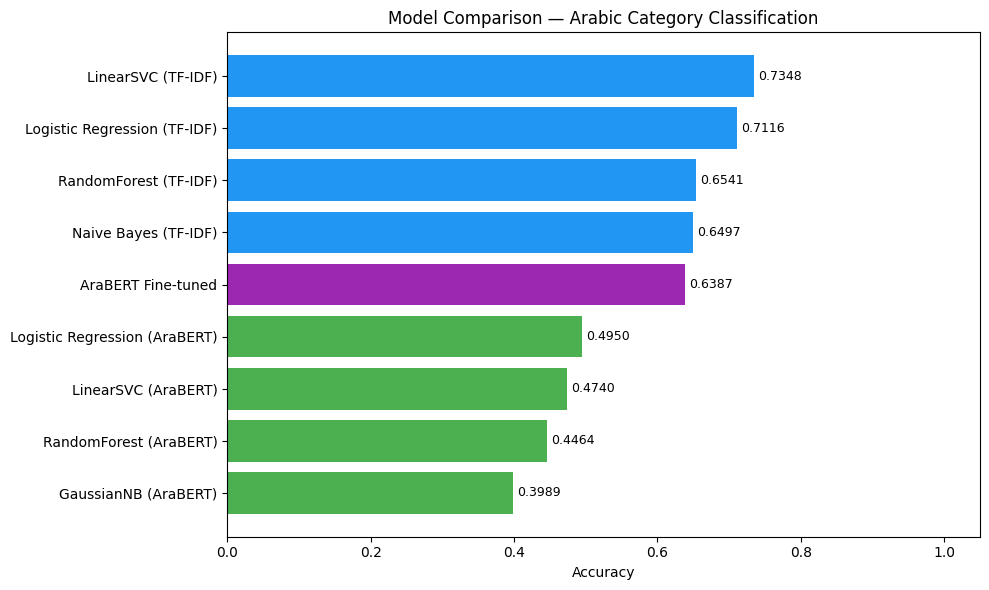

In [38]:
## Build the predictions map (all models including BERT):
pred_map_all = {
    'MultinomialNB (TF-IDF)'       : y_pred_nb,
    'GaussianNB (AraBERT)'         : y_pred_gnb,
    'LinearSVC (TF-IDF)'           : y_pred_svm_tfidf,
    'LinearSVC (AraBERT)'          : y_pred_svm_bert,
    'LogisticRegression (TF-IDF)'  : y_pred_lr_tfidf,
    'LogisticRegression (AraBERT)' : y_pred_lr_bert,
    'RandomForest (TF-IDF)'        : y_pred_rf_tfidf,
    'RandomForest (AraBERT)'       : y_pred_rf_bert,
    'AraBERT Fine-tuned'           : bert_preds,
}

## Accuracy bar chart:
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#9C27B0' if 'Fine-tuned' in m else '#2196F3' if 'TF-IDF' in m else '#4CAF50'
          for m in results_df_final['Model']]
ax.barh(results_df_final['Model'], results_df_final['Accuracy'], color=colors)
ax.set_xlabel('Accuracy')
ax.set_title('Model Comparison — Arabic Category Classification')
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
for bar, v in zip(ax.patches, results_df_final['Accuracy']):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

#### Classification Report (Best Model):

In [39]:
## Find the best model from all results (including BERT):
best_model_name = results_df_final.iloc[0]['Model']
print(f'Best model: {best_model_name}')
print(classification_report(y_te, pred_map_all[best_model_name],
                             target_names=label_encoder.classes_, digits=4))

Best model: LinearSVC (TF-IDF)
                  precision    recall  f1-score   support

 الاقتصاد والعمل     0.6964    0.7358    0.7156        53
  البيئة والطاقة     0.7778    0.7609    0.7692        92
      البيولوجيا     0.4118    0.7778    0.5385         9
         التاريخ     0.7838    0.8169    0.8000        71
         الترفيه     0.7500    0.8571    0.8000         7
          التطوع     0.8333    1.0000    0.9091         5
         التعليم     0.7374    0.6348    0.6822       115
     التكنولوجيا     0.7111    0.7619    0.7356        84
         الثقافة     0.7794    0.7518    0.7653       141
       الجغرافيا     0.6512    0.8000    0.7179        35
           الدين     0.9286    0.5652    0.7027        23
         الرياضة     0.6250    0.7692    0.6897        13
  السفر والسياحة     0.6667    0.5714    0.6154         7
السياسة والقانون     0.7692    0.8108    0.7895        37
           الصحة     0.8182    0.7642    0.7902       106
          العلوم     0.6339    0.6636   

#### Confusion Matrix (Best Model):

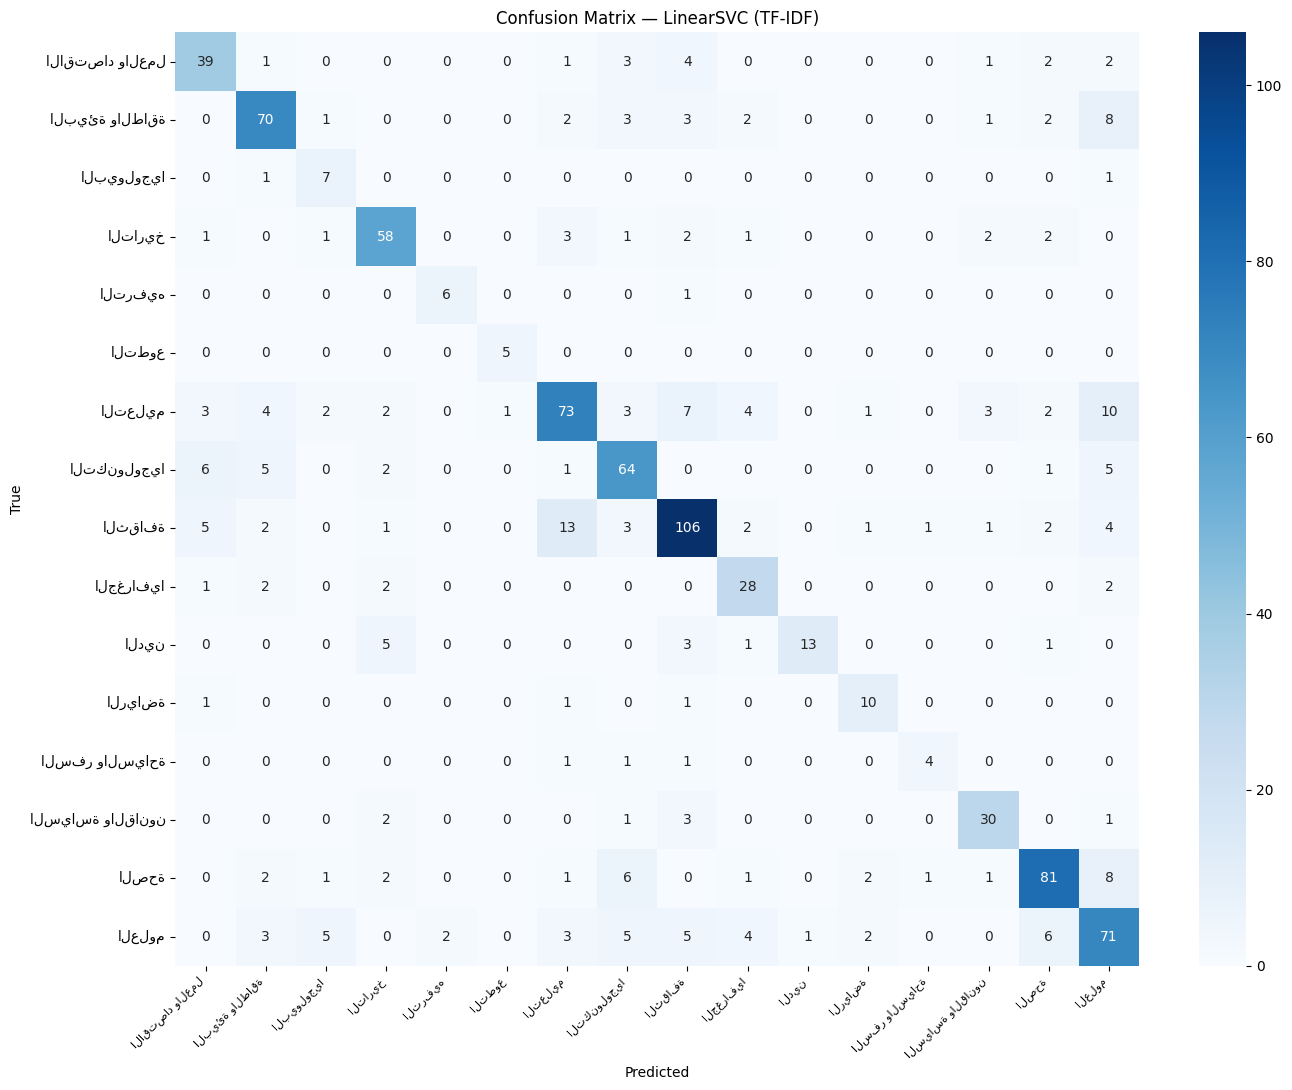

In [40]:
cm = confusion_matrix(y_te, pred_map_all[best_model_name])
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title(f'Confusion Matrix — {best_model_name}')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()